# Qwen3-8B emotion-vector extraction

Extracts pooled residual activations from the full 1,120-story dataset and constructs training-only emotion directions. Uses NVIDIA CUDA with 4-bit NF4 weights. No neutral-transcript PCA correction or held-out evaluation is performed.


## 1. Dependencies
Installs model-loading and analysis libraries in the active notebook kernel.


In [1]:
%pip -q install "transformers>=4.51.0,<5" "accelerate>=1.6,<2" "bitsandbytes>=0.45,<1" safetensors numpy pandas matplotlib tqdm


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Configuration
Defines dataset and output paths, CUDA device, token pooling, and expected full-dataset coverage.


In [2]:
import gc, hashlib, importlib.metadata, json, os, platform, random, shutil, time
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

DEVICE = torch.device("cuda:0")
if not torch.cuda.is_available():
    raise RuntimeError("This NF4 configuration requires an NVIDIA CUDA GPU visible to this kernel.")
print("GPU:", torch.cuda.get_device_name(DEVICE))
print("GPU memory (GiB):", round(torch.cuda.get_device_properties(DEVICE).total_memory / 2**30, 2))

MODEL_ID = "Qwen/Qwen3-8B"
# Paste the resolved SHA from a previous run to reproduce it exactly.
MODEL_REVISION = "main"
START_TOKEN_INDEX = 49  # 50th story token, inclusive
MAX_STORY_TOKENS = 512  # reject longer stories; never silently truncate
DATA_PATH = Path("data/emotion_stories_qwen_full1120.jsonl").expanduser().resolve()
OUTPUT_ROOT = Path("outputs/emotion_extraction").expanduser().resolve()
EXPECTED_TOPIC_IDS = set(range(20))
STORIES_PER_PAIR = 4
EXPECTED_SPLIT_TOPICS = {"train": set(range(14)), "validation": set(range(14,17)), "test": set(range(17,20))}
EXPECTED_EMOTIONS = [
    'desperate', 'nervous', 'surprised', 'calm', 'angry', 'loving', 'sad',
    'afraid', 'inspired', 'happy', 'guilty', 'proud', 'frustrated', 'hopeful',
]
SEED = 180
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print("Working directory:", Path.cwd())
print("Dataset:", DATA_PATH)
print("Outputs:", OUTPUT_ROOT)


GPU: Tesla T4
GPU memory (GiB): 14.56
Working directory: /content
Dataset: /content/data/emotion_stories_qwen_full1120.jsonl
Outputs: /content/outputs/emotion_extraction


## 3. Dataset validation
Loads external JSONL and verifies unique stories, 14 emotions, 20 topics, four stories per pair, and topic-level splits.


In [3]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"No dataset at {DATA_PATH}. Set DATA_PATH to the JSONL file accessible to this notebook kernel.")

def read_story_jsonl(path):
    records = []
    for line_number, line in enumerate(path.read_text(encoding='utf-8-sig').splitlines(), 1):
        if not line.strip():
            continue
        try:
            record = json.loads(line)
        except json.JSONDecodeError as exc:
            raise ValueError(f"Invalid JSON on line {line_number}: {exc}") from exc
        if not isinstance(record, dict):
            raise ValueError(f"Line {line_number} must contain one JSON object.")
        records.append(record)
    return records

rows = read_story_jsonl(DATA_PATH)
if not rows:
    raise ValueError("Dataset is empty.")
required = {'id', 'emotion', 'topic_id', 'text', 'split'}
for i, r in enumerate(rows, 1):
    missing = required - r.keys()
    if missing:
        raise ValueError(f"Record {i} is missing fields: {sorted(missing)}")
    if not isinstance(r['id'], str) or not r['id'].strip():
        raise ValueError(f"Record {i} needs a nonempty string ID.")
    if not isinstance(r['text'], str) or not r['text'].strip():
        raise ValueError(f"Record {i} needs nonempty story text.")
    if r['emotion'] not in EXPECTED_EMOTIONS:
        raise ValueError(f"Record {i} has unexpected emotion: {r['emotion']}")
    if r['split'] not in {'train', 'validation', 'test'}:
        raise ValueError(f"Record {i} has an invalid split.")
assert len({r['id'] for r in rows}) == len(rows), "Duplicate IDs."
normalize_text = lambda text: ' '.join(text.casefold().split())
assert len({normalize_text(r['text']) for r in rows}) == len(rows), "Duplicate story text."
topic_splits, id_to_topics = {}, {}
for r in rows:
    key = r.get('topic', str(r['topic_id']))
    topic_splits.setdefault(key, set()).add(r['split'])
    id_to_topics.setdefault(str(r['topic_id']), set()).add(key)
assert all(len(v) == 1 for v in topic_splits.values()), "Topic leakage across splits."
assert all(len(v) == 1 for v in id_to_topics.values()), "A topic ID maps to multiple topic texts."
emotions = sorted({r['emotion'] for r in rows})
assert set(emotions) == set(EXPECTED_EMOTIONS), "Some expected emotions are missing."
assert all(any(r['emotion'] == e and r['split'] == 'train' for r in rows) for e in emotions)
# Full project design: 14 emotions × 20 topics × 4 stories.
for r in rows:
    if type(r['topic_id']) is not int or r['topic_id'] not in EXPECTED_TOPIC_IDS:
        raise ValueError(f"Invalid topic_id for {r['id']}; expected integers 0–19.")
    if type(r.get('story_index')) is not int or r['story_index'] not in range(STORIES_PER_PAIR):
        raise ValueError(f"Invalid/missing story_index for {r['id']}; expected integers 0–3.")
    if r['topic_id'] not in EXPECTED_SPLIT_TOPICS[r['split']]:
        raise ValueError(f"Unexpected topic split for {r['id']}.")
pair_counts = Counter((r['emotion'],r['topic_id']) for r in rows)
expected_pairs = {(e,t) for e in EXPECTED_EMOTIONS for t in EXPECTED_TOPIC_IDS}
bad_pairs = {pair: pair_counts[pair] for pair in expected_pairs if pair_counts[pair] != STORIES_PER_PAIR}
if bad_pairs or set(pair_counts) != expected_pairs:
    raise ValueError(f"Incomplete/full-dataset coverage mismatch: {bad_pairs}")
for e,t in expected_pairs:
    indices = [r['story_index'] for r in rows if r['emotion']==e and r['topic_id']==t]
    if sorted(indices) != list(range(STORIES_PER_PAIR)):
        raise ValueError(f"Duplicate/missing story indices for {e}, topic {t}.")
expected_size = len(EXPECTED_EMOTIONS)*len(EXPECTED_TOPIC_IDS)*STORIES_PER_PAIR
if len(rows) != expected_size:
    raise ValueError(f"Expected {expected_size} stories, received {len(rows)}.")
expected_counts = {s:len(ts)*len(EXPECTED_EMOTIONS)*STORIES_PER_PAIR for s,ts in EXPECTED_SPLIT_TOPICS.items()}
if dict(Counter(r['split'] for r in rows)) != expected_counts:
    raise ValueError("Split counts do not match the full design.")
print('Full coverage verified:',len(expected_pairs),'emotion/topic pairs.')
word_counts = [len(r['text'].split()) for r in rows]
print('Loaded:', DATA_PATH, '| Stories:', len(rows))
print(pd.crosstab(pd.Series([r['emotion'] for r in rows], name='emotion'),
                  pd.Series([r['split'] for r in rows], name='split')))
print('Words: min', min(word_counts), '| max', max(word_counts))
print('Review status:', Counter(r.get('review_status', 'unspecified') for r in rows))
print('Emotion/topic count range:', min(Counter((r['emotion'], str(r['topic_id'])) for r in rows).values()),
      'to', max(Counter((r['emotion'], str(r['topic_id'])) for r in rows).values()))
print('Example intended label:', rows[0]['emotion'])
print(rows[0]['text'])


Full coverage verified: 280 emotion/topic pairs.
Loaded: /content/data/emotion_stories_qwen_full1120.jsonl | Stories: 1120
split       test  train  validation
emotion                            
afraid        12     56          12
angry         12     56          12
calm          12     56          12
desperate     12     56          12
frustrated    12     56          12
guilty        12     56          12
happy         12     56          12
hopeful       12     56          12
inspired      12     56          12
loving        12     56          12
nervous       12     56          12
proud         12     56          12
sad           12     56          12
surprised     12     56          12
Words: min 69 | max 159
Review status: Counter({'pending_human_review': 1120})
Emotion/topic count range: 4 to 4
Example intended label: desperate
The morning sun filtered through the curtains as Clara sat on the edge of her bed, staring at the ceiling. Her hands trembled slightly, and she kept check

## 4. Model loading
Pins the model revision, checks token lengths without truncation, and loads Qwen3-8B in 4-bit NF4.


In [4]:
from huggingface_hub import HfApi
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

resolved_revision = HfApi().model_info(MODEL_ID, revision=MODEL_REVISION).sha
print("Pinned model revision:", resolved_revision)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=resolved_revision)

# Validate token lengths before downloading/loading the model weights.
encoded = [tokenizer(r['text'], add_special_tokens=False)['input_ids'] for r in rows]
lengths = [len(ids) for ids in encoded]
assert min(lengths) > START_TOKEN_INDEX, "A story has no tokens after the pooling start."
assert max(lengths) <= MAX_STORY_TOKENS, (
    f"Longest story has {max(lengths)} tokens. Review it or explicitly raise MAX_STORY_TOKENS."
)
print("Token lengths:", min(lengths), "to", max(lengths))

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=resolved_revision,
    quantization_config=quant_config,
    torch_dtype=torch.float16,
    device_map={'': str(DEVICE)},
    low_cpu_mem_usage=True,
    attn_implementation='sdpa',
)
model.eval()
model.config.use_cache = False
blocks = model.model.layers
LAYER_INDICES = list(range(len(blocks)))
MAIN_LAYER_INDEX = min(len(blocks) - 1, round(2 * len(blocks) / 3) - 1)
print("Blocks:", len(blocks), "Hidden size:", model.config.hidden_size)
print("Main block index:", MAIN_LAYER_INDEX, "(0-based; heuristic, not tuned)")
print("Model footprint (GiB):", round(model.get_memory_footprint() / 2**30, 2))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Pinned model revision: b968826d9c46dd6066d109eabc6255188de91218


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

... (9 outputs left out)

model-00004-of-00005.safetensors:   0%|          | 0.00/3.19G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Blocks: 36 Hidden size: 4096
Main block index: 23 (0-based; heuristic, not tuned)
Model footprint (GiB): 5.55


## 5. Run metadata
Fingerprints the dataset, model, and extraction settings; creates a reproducible checkpoint directory.


In [5]:
versions = {name: importlib.metadata.version(name) for name in
            ['torch', 'transformers', 'accelerate', 'bitsandbytes', 'huggingface_hub', 'numpy']}
dataset_jsonl = ''.join(json.dumps(r, ensure_ascii=False, sort_keys=True) + '\n' for r in rows)
dataset_sha = hashlib.sha256(dataset_jsonl.encode()).hexdigest()
config = dict(
    model_id=MODEL_ID, model_revision=resolved_revision,
    quantization=quant_config.to_dict(), dtype='float16',
    residual_location='decoder_block_output_before_final_rmsnorm',
    layer_indices=LAYER_INDICES, main_layer_index=MAIN_LAYER_INDEX,
    start_token_index=START_TOKEN_INDEX, max_story_tokens=MAX_STORY_TOKENS,
    input_format='plain_text_no_special_tokens_no_chat_wrapper',
    pooling='float32_token_mean', centering='equal_weight_mean_of_train_emotion_means',
    neutral_pca_removed=False, dataset_sha256=dataset_sha,
    dataset_design=dict(stories_per_pair=STORIES_PER_PAIR, split_topics={k: sorted(v) for k,v in EXPECTED_SPLIT_TOPICS.items()}),
    package_versions=versions, extraction_code_version='2.0-portable-full-dataset',
)
run_id = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:16]
RUN_DIR = OUTPUT_ROOT / run_id
CHECKPOINT_DIR = RUN_DIR / 'checkpoints'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
manifest = dict(run_id=run_id, config=config, gpu=torch.cuda.get_device_name(DEVICE),
                python=platform.python_version(), intended_labels=emotions,
                note='Full synthetic dataset; review status retained per story. No held-out claims.')
manifest_path = RUN_DIR / 'manifest.json'
if manifest_path.exists():
    assert json.loads(manifest_path.read_text())['config'] == config
manifest_path.write_text(json.dumps(manifest, indent=2))
(RUN_DIR / 'stories.jsonl').write_text(dataset_jsonl)
(RUN_DIR / 'environment.json').write_text(json.dumps(versions, indent=2))
print('Run:', run_id, 'Output:', RUN_DIR)


Run: ab1333f49024705c Output: /content/outputs/emotion_extraction/ab1333f49024705c


## 6. Extraction smoke check
Captures decoder-block outputs, averages from token 50, and verifies that hooks preserve the model output.


In [6]:
def extract_one(input_ids, verify=False):
    ids = torch.tensor([input_ids], dtype=torch.long, device=DEVICE)
    pooled = {}
    final_block = {}
    handles = []

    def make_hook(index):
        def hook(module, args, output):
            hidden = output[0] if isinstance(output, tuple) else output
            assert hidden.ndim == 3 and hidden.shape[0] == 1
            # FP32 accumulation; only this small pooled vector leaves the GPU.
            pooled[index] = hidden[0, START_TOKEN_INDEX:].float().mean(dim=0).cpu().numpy()
            if verify and index == len(blocks) - 1:
                final_block['hidden'] = hidden.detach().clone()
        return hook

    try:
        for index in LAYER_INDICES:
            handles.append(blocks[index].register_forward_hook(make_hook(index)))
        with torch.inference_mode():
            output = model.model(input_ids=ids, attention_mask=torch.ones_like(ids),
                                 use_cache=False, output_hidden_states=False, return_dict=True)
            if verify:
                last_with_hooks = output.last_hidden_state.detach().clone()
                expected_last = model.model.norm(final_block['hidden'])
                torch.testing.assert_close(expected_last, last_with_hooks, rtol=1e-3, atol=1e-3)
        del output
    finally:
        for handle in handles:
            handle.remove()

    if verify:
        with torch.inference_mode():
            baseline = model.model(input_ids=ids, attention_mask=torch.ones_like(ids),
                                   use_cache=False, output_hidden_states=False, return_dict=True)
            torch.testing.assert_close(baseline.last_hidden_state, last_with_hooks,
                                       rtol=1e-3, atol=1e-3)
        del baseline, last_with_hooks, expected_last
        final_block.clear()

    result = np.stack([pooled[index] for index in LAYER_INDICES]).astype(np.float32)
    assert result.shape == (len(LAYER_INDICES), model.config.hidden_size)
    assert np.isfinite(result).all(), 'Non-finite activations.'
    return result

start = time.monotonic()
smoke = extract_one(encoded[0], verify=True)
torch.cuda.synchronize(DEVICE)
print('Smoke check passed:', smoke.shape)
print(f'Two forward passes + checks took {time.monotonic() - start:.1f} seconds.')


Smoke check passed: (36, 4096)
Two forward passes + checks took 5.4 seconds.


## 7. Full-dataset extraction
Processes all 1,120 stories and reuses matching per-story checkpoints before saving the combined activation array.


In [7]:
activations = []
for r, input_ids in tqdm(list(zip(rows, encoded)), desc='Extracting stories'):
    key = hashlib.sha256(r['id'].encode()).hexdigest()[:24]
    checkpoint = CHECKPOINT_DIR / f'{key}.npz'
    if checkpoint.exists():
        with np.load(checkpoint, allow_pickle=False) as saved:
            assert str(saved['story_id'].item()) == r['id']
            assert str(saved['run_id'].item()) == run_id
            values = saved['pooled'].copy()
        assert values.shape == (len(LAYER_INDICES), model.config.hidden_size)
        assert np.isfinite(values).all()
    else:
        values = extract_one(input_ids)
        temp = checkpoint.with_suffix('.tmp')
        with temp.open('wb') as f:
            np.savez_compressed(f, pooled=values, story_id=np.array(r['id']), run_id=np.array(run_id))
        os.replace(temp, checkpoint)
    activations.append(values)

activations = np.stack(activations)  # stories × layers × hidden size
np.savez_compressed(RUN_DIR / 'story_activations.npz', pooled=activations,
                    story_ids=np.array([r['id'] for r in rows]),
                    emotions=np.array([r['emotion'] for r in rows]),
                    splits=np.array([r['split'] for r in rows]),
                    token_counts=np.array(lengths), layer_indices=np.array(LAYER_INDICES))
print('Saved pooled activations:', activations.shape)
print('Peak GPU allocated (GiB):', round(torch.cuda.max_memory_allocated(DEVICE) / 2**30, 2))


Extracting stories:   0%|          | 0/1120 [00:00<?, ?it/s]

Saved pooled activations: (1120, 36, 4096)
Peak GPU allocated (GiB): 6.82


## 8. Emotion directions
Computes emotion means from training stories only, then saves mean-centered raw and unit directions at every block.


In [8]:
means = []
train_counts = {}
for emotion in emotions:
    indices = [i for i, r in enumerate(rows) if r['emotion'] == emotion and r['split'] == 'train']
    assert indices
    train_counts[emotion] = len(indices)
    means.append(activations[indices].mean(axis=0))
means = np.stack(means).astype(np.float32)  # emotions × layers × hidden
center = means.mean(axis=0)
raw_vectors = means - center[None, :, :]
norms = np.linalg.norm(raw_vectors, axis=-1, keepdims=True)
assert np.all(norms > 1e-8), 'Degenerate direction; inspect the dataset.'
unit_vectors = raw_vectors / norms
assert np.max(np.abs(raw_vectors.mean(axis=0))) < 1e-3
assert np.isfinite(unit_vectors).all()
np.testing.assert_allclose(np.linalg.norm(unit_vectors, axis=-1), 1, atol=1e-5)

np.savez_compressed(RUN_DIR / 'emotion_vectors.npz',
    emotion_names=np.array(emotions), layer_indices=np.array(LAYER_INDICES),
    raw_vectors=raw_vectors, unit_vectors=unit_vectors,
    emotion_means=means, center=center, vector_norms=norms[..., 0],
    main_layer_index=np.array(MAIN_LAYER_INDEX))
(RUN_DIR / 'train_counts.json').write_text(json.dumps(train_counts, indent=2))
print('Vectors:', raw_vectors.shape, '(emotions, layers, hidden size)')
print('Training stories per emotion:', train_counts)


Vectors: (14, 36, 4096) (emotions, layers, hidden size)
Training stories per emotion: {'afraid': 56, 'angry': 56, 'calm': 56, 'desperate': 56, 'frustrated': 56, 'guilty': 56, 'happy': 56, 'hopeful': 56, 'inspired': 56, 'loving': 56, 'nervous': 56, 'proud': 56, 'sad': 56, 'surprised': 56}


## 9. Vector similarity
Plots cosine similarities at the selected block as descriptive geometry, without evaluating held-out performance.


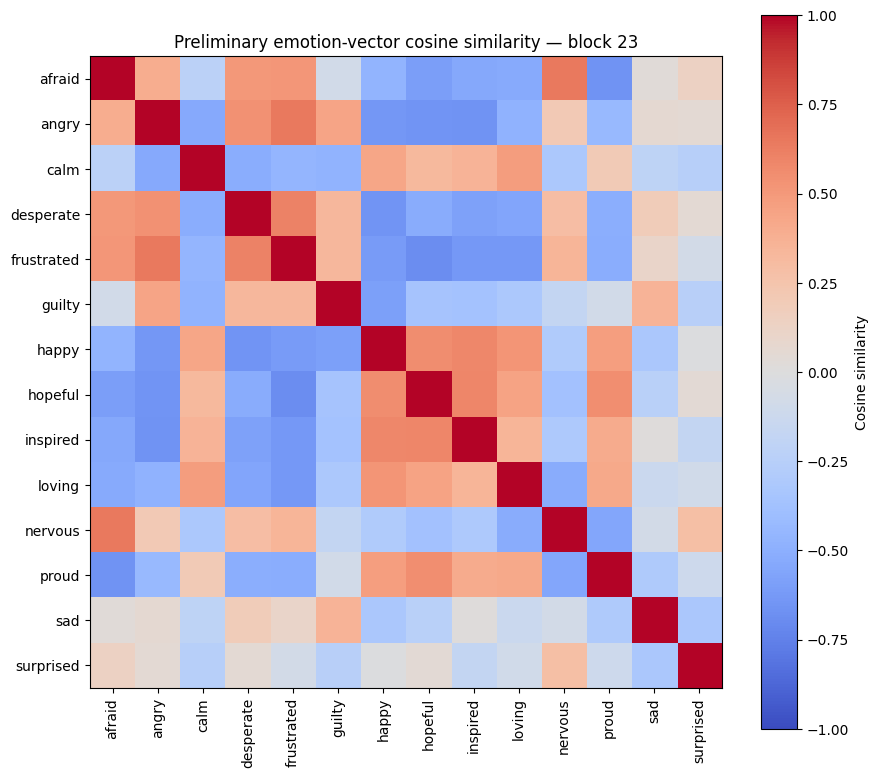

In [9]:
import matplotlib.pyplot as plt
layer_axis = LAYER_INDICES.index(MAIN_LAYER_INDEX)
v = unit_vectors[:, layer_axis, :]
similarity = v @ v.T
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(similarity, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(emotions)), emotions, rotation=90)
ax.set_yticks(range(len(emotions)), emotions)
ax.set_title(f'Preliminary emotion-vector cosine similarity — block {MAIN_LAYER_INDEX}')
fig.colorbar(im, ax=ax, label='Cosine similarity')
fig.tight_layout()
fig.savefig(RUN_DIR / 'cosine_similarity.png', dpi=160)
plt.show()


## 10. Export
Packages activations, vectors, dataset, and run metadata into a local ZIP file.


In [11]:
handoff = f"""Qwen3-8B emotion vectors — full dataset
Run: {run_id}
Model revision: {resolved_revision}
Quantization: bitsandbytes NF4, double quantization, float16 compute
Residual: decoder block output, before final RMSNorm; 0-based blocks
Plain story token mean from token 50 inclusive (Python index 49)
Raw mean-centering only; no neutral-transcript PCA removal
emotion_vectors.npz arrays: raw_vectors / unit_vectors [emotion, block, hidden]
Read emotion_names and layer_indices to recover ordering. Do not guess ordering.
Main block index: {MAIN_LAYER_INDEX}
Train counts: {json.dumps(train_counts)}
Full dataset: 1,120 stories, 784 train / 168 validation / 168 test.
Vectors use train only; no held-out evaluation has been performed.
Use the same revision, quantization and hook location downstream.
Steering strengths require calibration, not direct reuse of paper coefficients.
"""
(RUN_DIR / 'README.txt').write_text(handoff)
# Archive outside RUN_DIR so the archive cannot include itself.
zip_path = shutil.make_archive(str(OUTPUT_ROOT / f'qwen_emotion_{run_id}'), 'zip', RUN_DIR)
print('Saved ZIP:', zip_path)
from IPython.display import FileLink, display
relative_zip = os.path.relpath(zip_path, Path.cwd())
display(FileLink(relative_zip))


Saved ZIP: /content/outputs/emotion_extraction/qwen_emotion_ab1333f49024705c.zip


/content/outputs/emotion_extraction/qwen_emotion_ab1333f49024705c.zip